# Challenge 1: Predict the Output
**Qiskit Fall Fest 2026 · Single-qubit circuits**

This notebook solves the three experiments in the supplied *challenge 1.pdf*.
Each circuit uses exactly **one qubit**, starts in $|0\rangle$, and measures into
one classical bit. Each experiment runs for **100 shots** on Qiskit's ideal local simulator.
The saved outputs are actual simulator results, not hardware measurements.

## 1. Predictions — before running the circuits

| Circuit | Gates before measurement | State before measurement | Prediction for 100 shots |
|:--|:--|:--|:--|
| A | X | $|1\rangle$ | 0 zeros, 100 ones |
| B | X, X | $|0\rangle$ | 100 zeros, 0 ones |
| C | H | $(|0\rangle+|1\rangle)/\sqrt{2}$ | About 50 zeros and 50 ones |

**Why?** The X gate flips the computational basis states, so
$X|0\rangle=|1\rangle$ and $XX|0\rangle=|0\rangle$.
The H gate creates an equal superposition. Squaring each amplitude gives
$P(0)=P(1)=|1/\sqrt{2}|^2=1/2$.

Circuit C does **not** always produce the same measurement outcome.
Exactly 50 of each is not guaranteed in a finite sample. Every shot begins with a
fresh $|0\rangle$ state and repeats the entire circuit.

## 2. Setup

Run the cells from top to bottom. If dependencies are missing, uncomment and run
the installation line below, then restart the kernel. No IBM account is needed.

In [1]:
# %pip install qiskit matplotlib pylatexenc

In [2]:
import sys
import qiskit
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from qiskit import QuantumCircuit
from qiskit.providers.basic_provider import BasicSimulator
from qiskit.visualization import plot_histogram

SHOTS = 100
SEED = 2026
print(f"Python: {sys.version.split()[0]}")
print(f"Qiskit: {qiskit.__version__}")
print(f"Matplotlib: {matplotlib.__version__}")
print(f"Shots per circuit: {SHOTS}")

Python: 3.12.14
Qiskit: 2.5.2
Matplotlib: 3.11.2
Shots per circuit: 100


## 3. Construct and display the circuits

`QuantumCircuit(1, 1)` allocates one qubit and one classical bit. Qiskit's
simulator initializes the qubit to $|0\rangle$, so no extra preparation gate is
needed. `measure(0, 0)` measures the qubit in the computational basis and stores
the result in the classical bit. Only X and H gates are used before measurement.

Circuit A


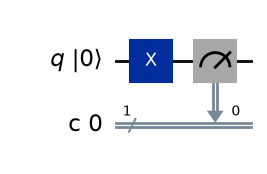

Circuit B


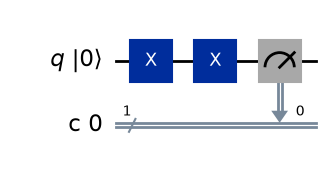

Circuit C


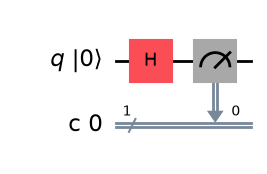

In [3]:
circuit_a = QuantumCircuit(1, 1, name="Circuit A")
circuit_a.x(0)
circuit_a.measure(0, 0)

circuit_b = QuantumCircuit(1, 1, name="Circuit B")
circuit_b.x(0)
circuit_b.x(0)
circuit_b.measure(0, 0)

circuit_c = QuantumCircuit(1, 1, name="Circuit C")
circuit_c.h(0)
circuit_c.measure(0, 0)

circuits = [circuit_a, circuit_b, circuit_c]
for circuit in circuits:
    print(circuit.name)
    figure = circuit.draw(output="mpl", initial_state=True)
    display(figure)
    plt.close(figure)

## 4. Execute each circuit for 100 shots

`BasicSimulator` samples measurement outcomes from the ideal quantum probabilities.
A fixed random seed makes this demonstration reproducible with the same software
versions. Set `SEED = None` and rerun for fresh random samples; this does not change
the underlying 50% probabilities of Circuit C.

In [4]:
simulator = BasicSimulator()
counts = {}
for circuit in circuits:
    result = simulator.run(circuit, shots=SHOTS, seed_simulator=SEED).result()
    raw_counts = result.get_counts()
    # Include both outcomes even when an outcome never occurs.
    counts[circuit.name] = {bit: raw_counts.get(bit, 0) for bit in ("0", "1")}
    print(f"{circuit.name}: {counts[circuit.name]}")

Circuit A: {'0': 0, '1': 100}
Circuit B: {'0': 100, '1': 0}
Circuit C: {'0': 49, '1': 51}


## 5. Measurement histograms

Each panel shows the observed counts from 100 shots. Dashed lines show predicted
counts: these are exact for the deterministic circuits and expected averages for C.

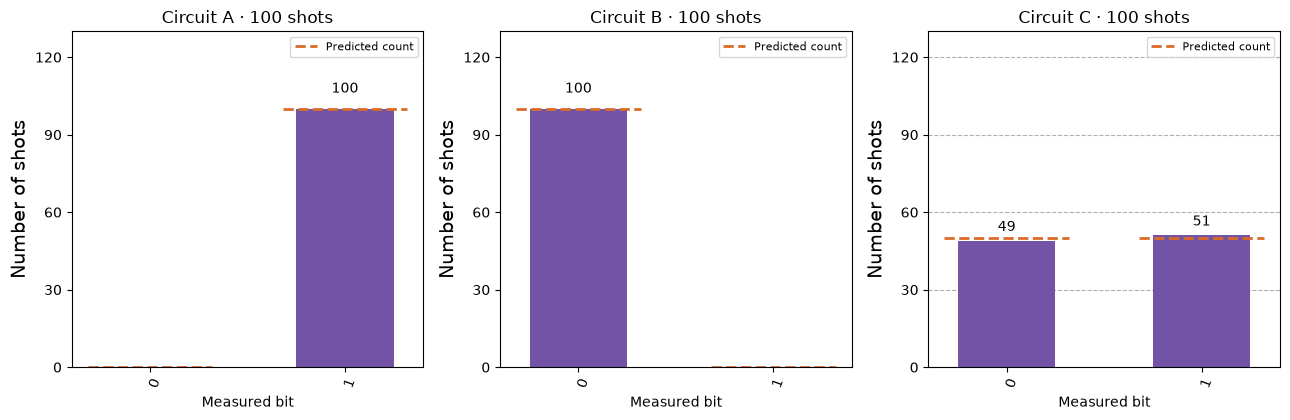

In [5]:
expected_counts = {
    "Circuit A": {"0": 0, "1": 100},
    "Circuit B": {"0": 100, "1": 0},
    "Circuit C": {"0": 50, "1": 50},
}
fig, axes = plt.subplots(1, 3, figsize=(13, 4.3))
for ax, circuit in zip(axes, circuits):
    name = circuit.name
    plot_histogram(counts[name], ax=ax, title=f"{name} · 100 shots", color="#7253A6")
    for index, bit in enumerate(("0", "1")):
        prediction = expected_counts[name][bit]
        ax.hlines(prediction, index - 0.32, index + 0.32,
                  colors="#DB6B27", linestyles="--", linewidth=2,
                  label="Predicted count" if index == 0 else None)
    ax.set_title(f"{name} · 100 shots")
    ax.set_ylim(0, 130)
    ax.set_xlabel("Measured bit")
    ax.set_ylabel("Number of shots")
    ax.legend(loc="upper right", fontsize=8)
fig.tight_layout()
display(fig)
plt.close(fig)

## 6. Compare predictions with actual results

In [6]:
rows = [
    "| Circuit | Predicted zeros / ones | Observed zeros / ones | Comparison |",
    "|:--|:--|:--|:--|",
]
for circuit in circuits:
    name = circuit.name
    observed = counts[name]
    expected = expected_counts[name]
    if name != "Circuit C":
        comparison = "Exact agreement" if observed == expected else "Unexpected result"
        predicted = f"{expected['0']} / {expected['1']}"
    else:
        predicted = "About 50 / 50"
        comparison = f"Zero count differs from 50 by {observed['0'] - 50:+d}; finite-shot sampling"
    rows.append(f"| {name} | {predicted} | {observed['0']} / {observed['1']} | {comparison} |")
display(Markdown("\n".join(rows)))

c = counts["Circuit C"]
display(Markdown(
    f"**Circuit C in this run:** {c['0']} zeros and {c['1']} ones, "
    f"giving observed frequencies {c['0']/SHOTS:.0%} and {c['1']/SHOTS:.0%}. "
    "The theoretical probabilities remain 50% each."
))

| Circuit | Predicted zeros / ones | Observed zeros / ones | Comparison |
|:--|:--|:--|:--|
| Circuit A | 0 / 100 | 0 / 100 | Exact agreement |
| Circuit B | 100 / 0 | 100 / 0 | Exact agreement |
| Circuit C | About 50 / 50 | 49 / 51 | Zero count differs from 50 by -1; finite-shot sampling |

**Circuit C in this run:** 49 zeros and 51 ones, giving observed frequencies 49% and 51%. The theoretical probabilities remain 50% each.

For Circuit C, the number of zeros follows a binomial distribution:
$N_0\sim\mathrm{Binomial}(100,0.5)$. Its mean is 50 and its standard deviation is
$\sqrt{100(0.5)(0.5)}=5$ counts. A modest imbalance is therefore expected and does
not contradict the prediction. Reusing a fixed simulator seed reproduces a sample;
it does not make the quantum measurement deterministic.

## 7. Verify the challenge constraints

In [7]:
for circuit in circuits:
    assert circuit.num_qubits == 1
    assert circuit.num_clbits == 1
    assert circuit.count_ops().get("measure", 0) == 1
    assert set(circuit.count_ops()) <= {"x", "h", "measure"}
    assert sum(counts[circuit.name].values()) == SHOTS
assert dict(circuit_a.count_ops()) == {"x": 1, "measure": 1}
assert dict(circuit_b.count_ops()) == {"x": 2, "measure": 1}
assert dict(circuit_c.count_ops()) == {"h": 1, "measure": 1}
assert counts["Circuit A"] == {"0": 0, "1": 100}
assert counts["Circuit B"] == {"0": 100, "1": 0}
# Do not assert an exact 50/50 split for a random sample.
print("All checks passed: one qubit, required gates, measurement, and 100 shots per circuit.")

All checks passed: one qubit, required gates, measurement, and 100 shots per circuit.


## Conclusion

- **One X gate:** flips the initial state to $|1\rangle$, so every ideal measurement is 1.
- **Two X gates:** undo each other, returning to $|0\rangle$, so every ideal measurement is 0.
- **One H gate:** gives 0 or 1 with equal probability; the measured counts fluctuate between independent runs.

**References:** Problem requirements: supplied *challenge 1.pdf*, page 1.
Simulator API: [IBM Quantum documentation — BasicSimulator](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.providers.basic_provider.BasicSimulator).